# 5. XGBoost

Same feature-availability comparison as notebooks 3 and 4, using XGBoost (with class-balanced sample weights) instead. Saves its results table for the three-model comparison in notebook 7.

In [ ]:
# Setup
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd if (cwd / "requirements.txt").exists() else cwd.parent
sys.path.append(str(project_root))

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix

from src.evaluate import cross_validate_xgboost, evaluate_xgboost_feature_set
from src.preprocessing import (
    get_feature_availability_sets,
    load_data,
)

sns.set_theme(style="whitegrid")

df = load_data()
feature_sets = get_feature_availability_sets(df)

classes = ["Dropout", "Enrolled", "Graduate"]

display({
    name: len(cols)
    for name, cols in feature_sets.items()
})

{'Day 1': 24, 'After Semester 1': 30, 'Full Data': 36}

## 5.1 XGBoost across Day 1 / Semester 1 / Full

In [2]:
xgb_feature_results = []
xgb_fitted = {}

for name, cols in feature_sets.items():

    result, pipe, X_test, y_test, y_pred = evaluate_xgboost_feature_set(
        df=df,
        feature_cols=cols,
        feature_set_name=name,
        return_split=True
    )

    xgb_feature_results.append(result)

    xgb_fitted[name] = {
        "pipeline": pipe,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": y_pred
    }

xgb_feature_results_df = pd.DataFrame(
    xgb_feature_results
)

display(xgb_feature_results_df.round(3))

,Feature Set,Accuracy,Macro F1,Macro Recall,Dropout Recall,Enrolled Recall,Graduate Recall
0,Day 1,0.592,0.561,0.569,0.570,0.497,0.640
1,After Semester 1,0.705,0.667,0.679,0.648,0.616,0.774
2,Full Data,0.737,0.702,0.715,0.694,0.660,0.792


In [3]:
# Save so 07_model_comparison.ipynb can load it without recomputing
output_path = project_root / "data" / "processed" / "xgb_feature_availability.csv"

xgb_feature_results_df.to_csv(
    output_path,
    index=False
)

## 5.2 Visualization

### 5.2.1 Macro F1 and Accuracy

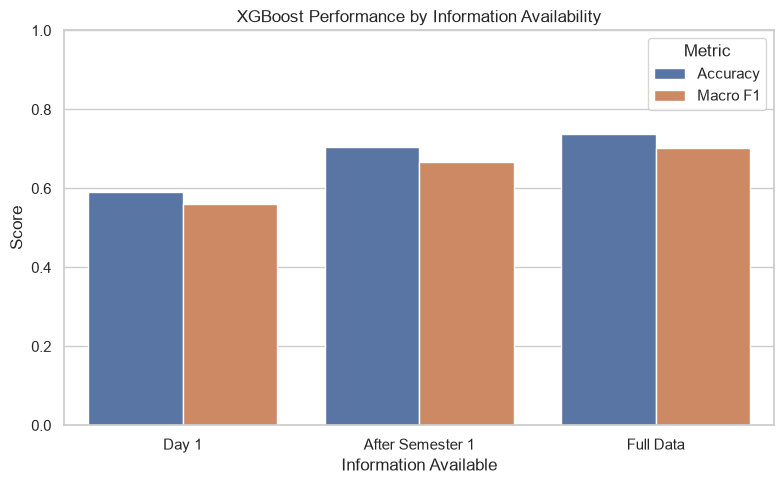

In [4]:
xgb_performance_long = xgb_feature_results_df.melt(
    id_vars="Feature Set",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=xgb_performance_long,
    x="Feature Set",
    y="Score",
    hue="Metric",
    ax=ax
)

ax.set_ylim(0, 1)
ax.set_title("XGBoost Performance by Information Availability")
ax.set_xlabel("Information Available")
ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

### 5.2.2 Per class Recall

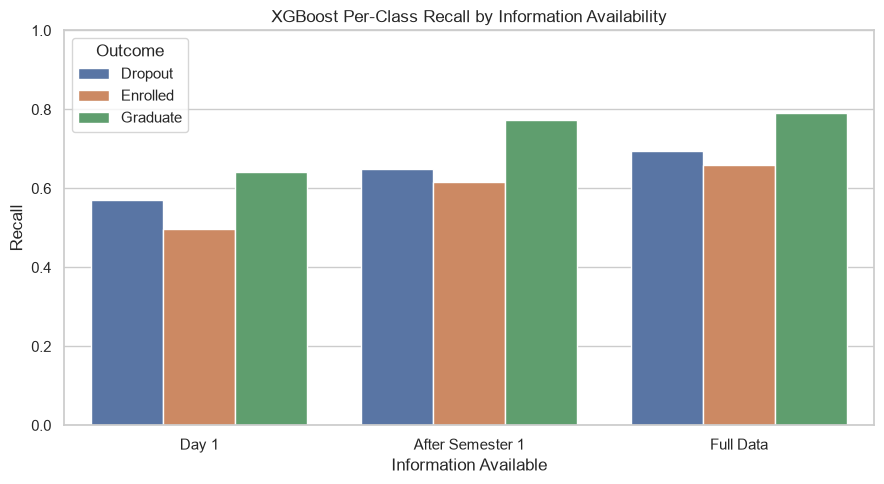

In [5]:
xgb_recall_long = xgb_feature_results_df.melt(
    id_vars="Feature Set",
    value_vars=[
        "Dropout Recall",
        "Enrolled Recall",
        "Graduate Recall"
    ],
    var_name="Outcome",
    value_name="Recall"
)

xgb_recall_long["Outcome"] = (
    xgb_recall_long["Outcome"]
    .str.replace(" Recall", "", regex=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=xgb_recall_long,
    x="Feature Set",
    y="Recall",
    hue="Outcome",
    ax=ax
)

ax.set_ylim(0, 1)
ax.set_title("XGBoost Per-Class Recall by Information Availability")
ax.set_xlabel("Information Available")
ax.set_ylabel("Recall")

plt.tight_layout()
plt.show()

### 5.2.3 Confusion Matrices

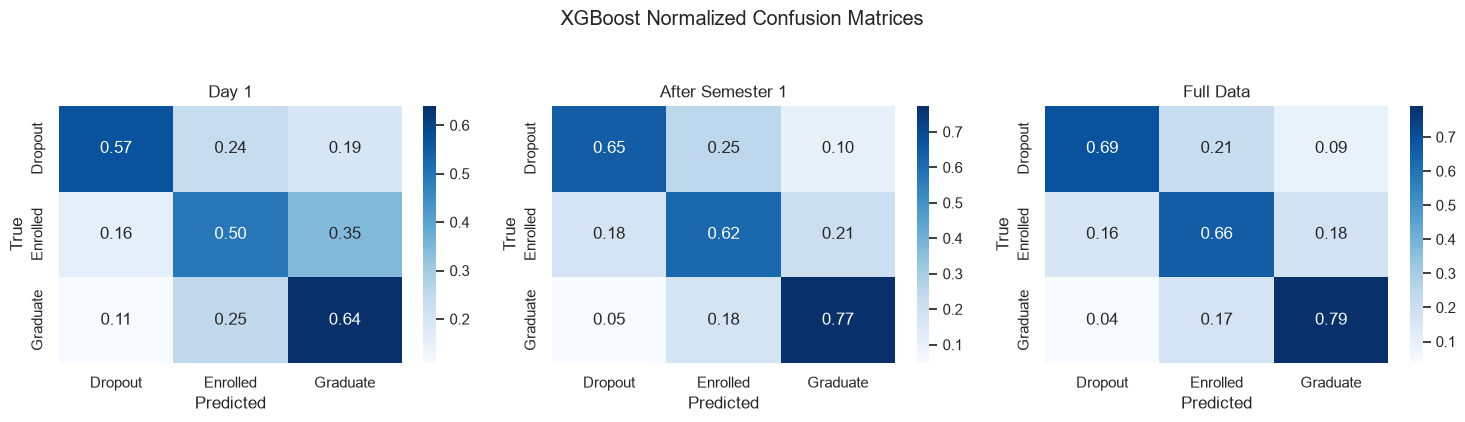

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, feature_sets.keys()):

    y_test = xgb_fitted[name]["y_test"]
    y_pred = xgb_fitted[name]["y_pred"]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=classes,
        normalize="true"
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle(
    "XGBoost Normalized Confusion Matrices",
    y=1.05
)

plt.tight_layout()
plt.show()

## 5.3 Stratified 5-fold CV

### 5.3.1 CV for all three information stages

In [7]:
xgb_cv_results = []

for name, cols in feature_sets.items():
    stage_cv = cross_validate_xgboost(
        df=df,
        feature_cols=cols,
        feature_set_name=name
    )

    xgb_cv_results.append(stage_cv)

xgb_cv_results_df = pd.concat(
    xgb_cv_results,
    ignore_index=True
)

display(xgb_cv_results_df.round(3))

,Feature Set,Fold,Accuracy,Macro F1,Macro Recall,Dropout Recall,Enrolled Recall,Graduate Recall
0,Day 1,1,0.620,0.579,0.582,0.579,0.465,0.703
1,Day 1,2,0.602,0.572,0.584,0.567,0.535,0.649
2,Day 1,3,0.626,0.590,0.603,0.539,0.566,0.704
3,Day 1,4,0.631,0.600,0.611,0.592,0.560,0.681
4,Day 1,5,0.588,0.550,0.557,0.542,0.468,0.661
5,After Semester 1,1,0.750,0.706,0.707,0.684,0.585,0.853
6,After Semester 1,2,0.713,0.674,0.682,0.697,0.579,0.771
7,After Semester 1,3,0.736,0.694,0.701,0.683,0.604,0.817
8,After Semester 1,4,0.738,0.694,0.697,0.683,0.579,0.830
9,After Semester 1,5,0.718,0.678,0.687,0.676,0.595,0.790


### 5.3.2 Mean ± SD CV table

In [8]:
cv_summary = (
    xgb_cv_results_df
    .groupby("Feature Set")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        SD_Accuracy=("Accuracy", "std"),

        Mean_Macro_F1=("Macro F1", "mean"),
        SD_Macro_F1=("Macro F1", "std"),

        Mean_Macro_Recall=("Macro Recall", "mean"),
        SD_Macro_Recall=("Macro Recall", "std"),

        Mean_Dropout_Recall=("Dropout Recall", "mean"),
        Mean_Enrolled_Recall=("Enrolled Recall", "mean"),
        Mean_Graduate_Recall=("Graduate Recall", "mean")
    )
    .reset_index()
)

display(cv_summary.round(3))

,Feature Set,Mean_Accuracy,SD_Accuracy,Mean_Macro_F1,SD_Macro_F1,Mean_Macro_Recall,SD_Macro_Recall,Mean_Dropout_Recall,Mean_Enrolled_Recall,Mean_Graduate_Recall
0,After Semester 1,0.731,0.015,0.689,0.013,0.695,0.010,0.685,0.588,0.812
1,Day 1,0.613,0.018,0.578,0.019,0.587,0.021,0.564,0.519,0.680
2,Full Data,0.762,0.006,0.722,0.003,0.729,0.005,0.722,0.628,0.836


In [9]:
for _, row in cv_summary.iterrows():

    print(row["Feature Set"])

    print(
        f"  Accuracy: "
        f"{row['Mean_Accuracy']:.3f} "
        f"+/- {row['SD_Accuracy']:.3f}"
    )

    print(
        f"  Macro F1: "
        f"{row['Mean_Macro_F1']:.3f} "
        f"+/- {row['SD_Macro_F1']:.3f}"
    )

    print(
        f"  Macro Recall: "
        f"{row['Mean_Macro_Recall']:.3f} "
        f"+/- {row['SD_Macro_Recall']:.3f}"
    )

    print(
        f"  Enrolled Recall: "
        f"{row['Mean_Enrolled_Recall']:.3f}"
    )

    print()

After Semester 1
  Accuracy: 0.731 +/- 0.015
  Macro F1: 0.689 +/- 0.013
  Macro Recall: 0.695 +/- 0.010
  Enrolled Recall: 0.588

Day 1
  Accuracy: 0.613 +/- 0.018
  Macro F1: 0.578 +/- 0.019
  Macro Recall: 0.587 +/- 0.021
  Enrolled Recall: 0.519

Full Data
  Accuracy: 0.762 +/- 0.006
  Macro F1: 0.722 +/- 0.003
  Macro Recall: 0.729 +/- 0.005
  Enrolled Recall: 0.628



### 5.3.3 CV Macro F1 plot

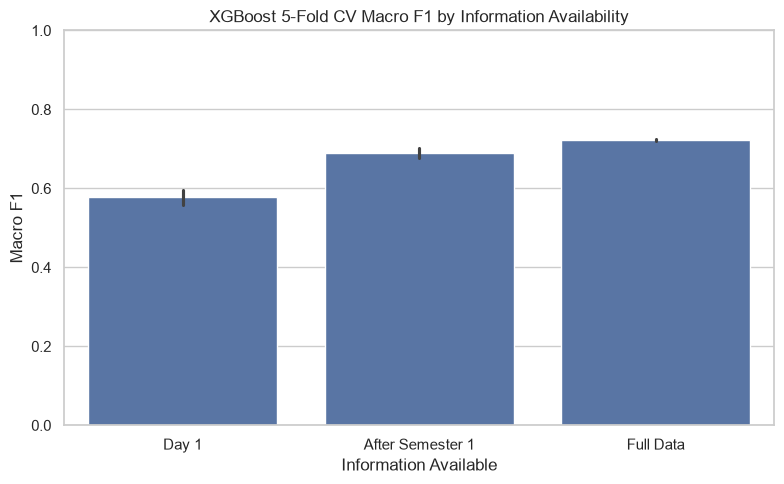

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=xgb_cv_results_df,
    x="Feature Set",
    y="Macro F1",
    errorbar="sd",
    ax=ax
)

ax.set_ylim(0, 1)
ax.set_title(
    "XGBoost 5-Fold CV Macro F1 by Information Availability"
)
ax.set_xlabel("Information Available")
ax.set_ylabel("Macro F1")

plt.tight_layout()
plt.show()